In [ ]:
from google.colab import files
import pandas as pd
from sklearn.preprocessing import StandardScaler

# Step 1: Upload the Excel file
uploaded = files.upload()

# Step 2: Load the Excel file
file_name = list(uploaded.keys())[0]
df = pd.read_excel(file_name)  # <-- FIXED

# Step 3: Separate datetime column and convert to datetime format
datetime_col = df.columns[0]
datetime_series = pd.to_datetime(df[datetime_col])  # Convert to datetime
numeric_df = df.drop(columns=[datetime_col])

# Step 4: Standardize only numeric columns
scaler = StandardScaler()
scaled_values = scaler.fit_transform(numeric_df)
df_scaled = pd.DataFrame(scaled_values, columns=numeric_df.columns)

# Step 5: Combine datetime with standardized data
df_final = pd.concat([datetime_series, df_scaled], axis=1)
df_final.rename(columns={df_final.columns[0]: datetime_col}, inplace=True)

# Step 6: Save and download as CSV
output_filename = "Standardized_Dataset.csv"
df_final.to_csv(output_filename, index=False)
files.download(output_filename)


Saving The Dataset.xlsx to The Dataset (1).xlsx


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import files
import pandas as pd
from sklearn.preprocessing import StandardScaler

# Step 1: Upload the CSV file
uploaded = files.upload()

Saving Standardized_Dataset.csv to Standardized_Dataset (2).csv


In [ ]:
import threading, time, sys

def keep_colab_alive(interval_sec=60):
    """Print a small heartbeat so Colab sees activity."""
    while True:
        # ‘flush’ forces the message to appear immediately
        print(f"⏰ still training {time.strftime('%H:%M:%S')}", flush=True)
        time.sleep(interval_sec)

# Start the daemon – it dies automatically when the notebook stops
threading.Thread(target=keep_colab_alive, daemon=True).start()

⏰ still training 09:23:55


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# ========================= RL (temporal CTDE, 2 agents: HVAC & Light) =========================
import torch, torch.nn as nn, torch.nn.functional as F
from torch.distributions import Normal
import numpy as np, pandas as pd, random, matplotlib.pyplot as plt
from collections import deque, namedtuple
import os, glob

# ─────────────────────────── Checkpoint / Metrics dirs ──────────────────
DRIVE_ROOT = "/content/drive/MyDrive"
CKPT_DIR = os.path.join(DRIVE_ROOT, "checkpoints") if os.path.isdir(DRIVE_ROOT) else "./checkpoints"
os.makedirs(CKPT_DIR, exist_ok=True)
METRICS_LIVE = os.path.join(CKPT_DIR, "run_metrics_live.csv")
print("✔ Using checkpoint dir:", CKPT_DIR)

# ─────────────────────────── Hyper-parameters ───────────────────────────
TAU        = 0.01
GAMMA      = 0.99
ACTOR_LR   = 3e-4
CRITIC_LR  = 1e-3
ALPHA_LR   = 3e-4

NUM_EPISODES = 10
BATCH_SIZE   = 256
BUFFER_SIZE  = 100_000
ACTION_DIM   = 1
N_AGENTS     = 2
EMBED_DIM    = 96
NUM_HEADS    = 4
NUM_LAYERS   = 2

# temporal enc
SEQ_LEN      = 8     # timesteps in the sliding window
TEMP_DIM     = 64    # temporal context vector size

HVAC_MIN, HVAC_MAX = 21.0, 25.0
PMV_MIN,  PMV_MAX  = -0.5, 0.5
EPS = 1e-6

# ─────────── HVAC–comfort/energy coupling (simple, tunable) ───────────
HVAC_SETPOINT_BASE = 23.0   # °C reference comfort setpoint
COOL_SENSITIVITY   = 0.12   # ~12% cooling change per +1 °C setpoint delta
PMV_PER_DEG        = 0.15   # PMV shift per +1 °C setpoint delta
COOL_CLAMP_MIN     = 0.30   # don't let cooling scale go below 30%
COOL_CLAMP_MAX     = 1.20   # allow slight overcooling if setpoint lower

# ─────────────────────────── Environment ────────────────────────────────
class DatasetEnv:
    """
    Temporal CTDE env (no PV/Battery).
    HVAC agent sets a temperature setpoint (°C) which scales cooling and shifts PMV.
    Lighting agent sets a ∈ (0,1) scaling of the baseline lighting energy.

    Dataset columns (hourly):
      Loads:  'Cooling ', 'Fans', ' Pumps', 'Lighting'
      Tariff: 'Tariff' (buy price) or infer from Cost/baseline energy
      Optional: 'Grid_CO2', 'Fanger PMV'/'PMV'
      'Date' must be parseable (adds time features).
    """
    def __init__(self, csv):
        df = pd.read_csv(csv, parse_dates=['Date'])

        # ---- time features from Date ----
        dt   = df['Date']
        hour = dt.dt.hour + dt.dt.minute/60.0
        dow  = dt.dt.dayofweek
        mon  = dt.dt.month

        df['tod_sin'] = np.sin(2*np.pi*hour/24.0)
        df['tod_cos'] = np.cos(2*np.pi*hour/24.0)
        df['dow_sin'] = np.sin(2*np.pi*dow/7.0)
        df['dow_cos'] = np.cos(2*np.pi*dow/7.0)
        df['mon_sin'] = np.sin(2*np.pi*(mon-1)/12.0)
        df['mon_cos'] = np.cos(2*np.pi*(mon-1)/12.0)
        df['is_weekend'] = (dow>=5).astype(np.float32)

        self.df       = df.reset_index(drop=True)
        self.obs_cols = [c for c in self.df.columns if c != 'Date']   # everything except Date
        self.obs_dim  = len(self.obs_cols)
        self.n        = len(self.df)
        self.idx      = 0

    def _row_obs(self, i):
        return self.df.loc[i, self.obs_cols].values.astype(np.float32)

    def reset(self):
        self.idx = 0
        obs_vec = self._row_obs(self.idx)                      # [D]
        obs     = np.tile(obs_vec, (N_AGENTS, 1))              # [2,D]
        return obs, self.df.loc[self.idx, 'Date']

    def step(self, hvac_sp, light_act):
        self.idx += 1
        done  = self.idx >= self.n - 1
        row   = self.df.loc[self.idx]
        date  = row['Date']

        # Baseline energy components (note exact column names incl. spaces)
        cooling0 = float(row['Cooling ']) if 'Cooling ' in row else 0.0
        fans     = float(row['Fans'])     if 'Fans'     in row else 0.0
        pumps    = float(row[' Pumps'])   if ' Pumps'   in row else 0.0
        light0   = float(row['Lighting']) if 'Lighting' in row else 0.0

        # HVAC action (setpoint °C) → scales cooling and shifts PMV
        sp = float(np.clip(hvac_sp, HVAC_MIN, HVAC_MAX))
        delta_sp = sp - HVAC_SETPOINT_BASE
        cool_scale = np.clip(1.0 - COOL_SENSITIVITY * delta_sp, COOL_CLAMP_MIN, COOL_CLAMP_MAX)
        cooling = cool_scale * cooling0

        # Lighting action a∈[0,1]
        a_light   = float(np.clip(light_act, 0.0, 1.0))
        light_kwh = a_light * light0

        # Tariff and CO2 (fallbacks if missing)
        baseline_energy = cooling0 + fans + pumps + light0
        if baseline_energy > 1e-8:
            tariff = float(row.get('Tariff', row.get('Cost', 0.0)/baseline_energy))
        else:
            tariff = float(row.get('Tariff', 0.0))
        grid_co2 = float(row.get('Grid_CO2', 0.4))  # kg/kWh default

        # Energy & cost
        energy_kwh = cooling + fans + pumps + light_kwh
        cost       = tariff * energy_kwh

        # Comfort penalty from PMV band (with setpoint shift)
        pmv_base = row.get('Fanger PMV', row.get('PMV', 0.0))
        pmv      = float(pmv_base) + PMV_PER_DEG * delta_sp
        penalty  = max(pmv - PMV_MAX, 0) + max(PMV_MIN - pmv, 0)

        reward  = -(cost + penalty)

        # Next obs (same structure)
        obs_vec = self._row_obs(self.idx)
        obs     = np.tile(obs_vec, (N_AGENTS, 1))

        # Info logging (for KPIs)
        info = {**row.drop(labels=['Date']).to_dict(), 'date': date}
        info['Cooling ']          = cooling
        info['Lighting']          = light_kwh
        info['Cost']              = cost
        info['Tariff']            = tariff
        info['Grid_CO2']          = grid_co2
        info['Fanger PMV']        = pmv
        info['Penalty']           = penalty
        info['Net_kWh']           = energy_kwh                     # +import amount (no export here)
        info['Net_kWh_district']  = float(row.get('Net_kWh_district', energy_kwh))

        return obs, reward, done, info

# ───────────────────────── Replay Buffer (with sequences) ───────────────
Transition = namedtuple('T', ('obs','act','rew','nxt','done','seq','nseq'))
class ReplayBuffer:
    def __init__(self, cap): self.buf = deque(maxlen=cap)
    def push(self,*a):       self.buf.append(Transition(*a))
    def sample(self,b):      return random.sample(self.buf,b)
    def __len__(self):       return len(self.buf)

# ───────────────────── Temporal Encoder (Transformer) ───────────────────
class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=4096):
        super().__init__()
        pe = torch.zeros(max_len, d_model)
        pos = torch.arange(0, max_len, dtype=torch.float32).unsqueeze(1)
        div = torch.exp(torch.arange(0, d_model, 2).float() * (-np.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(pos * div)
        pe[:, 1::2] = torch.cos(pos * div)
        self.register_buffer('pe', pe.unsqueeze(0), persistent=False)
    def forward(self, x):  # [B,L,D]
        return x + self.pe[:, :x.size(1)]

class TemporalEncoder(nn.Module):
    """Transformer over last SEQ_LEN raw obs vectors → context [TEMP_DIM]."""
    def __init__(self, input_dim, model_dim=TEMP_DIM, nhead=NUM_HEADS, num_layers=NUM_LAYERS):
        super().__init__()
        self.proj = nn.Linear(input_dim, model_dim)
        self.pos  = PositionalEncoding(model_dim, max_len=4096)
        enc = nn.TransformerEncoderLayer(d_model=model_dim, nhead=nhead,
                                         dim_feedforward=4*model_dim, activation='gelu',
                                         batch_first=True)
        self.tr = nn.TransformerEncoder(enc, num_layers=num_layers)
    def forward(self, seq):       # seq: [B, L, D]
        x = self.proj(seq)
        x = self.pos(x)
        x = self.tr(x)            # [B,L,D]
        return x[:, -1, :]        # context at last step

# ───────────────────── Multi-head Attention (per-timestep) ──────────────
class MultiHeadAttention(nn.Module):
    def __init__(self, inp_dim, emb_dim, heads):
        super().__init__()
        assert emb_dim % heads == 0
        self.h = heads; self.hd = emb_dim // heads; self.scale = self.hd ** -0.5
        self.q_proj = nn.Linear(inp_dim, emb_dim)
        self.k_proj = nn.Linear(inp_dim, emb_dim)
        self.v_proj = nn.Linear(inp_dim, emb_dim)
        self.out    = nn.Linear(emb_dim, emb_dim)
    def forward(self, x):         # x: [B,N,TOKEN_DIM]
        B, N, _ = x.shape
        q = self.q_proj(x).view(B, self.h, N, self.hd)
        k = self.k_proj(x).view(B, self.h, N, self.hd)
        v = self.v_proj(x).view(B, self.h, N, self.hd)
        scores = (q @ k.transpose(-2, -1)) * self.scale
        w = F.softmax(scores, dim=-1)
        attn = (w @ v).transpose(1, 2).reshape(B, N, -1)
        return self.out(attn)

# ───────────────────────── Actors / Critic (with ctx) ───────────────────
def clamp_logstd(x): return x.clamp(-20,2)

class BaseActor(nn.Module):
    """Shared skeleton: embed per-agent obs + ctx → token attention → MLP head."""
    def __init__(self, obs_dim, ctx_dim=TEMP_DIM, token_index=0, squasher='tanh'):
        super().__init__()
        self.embed = nn.Linear(obs_dim, EMBED_DIM)
        self.ctx_p = nn.Linear(ctx_dim, EMBED_DIM)
        self.attn  = MultiHeadAttention(EMBED_DIM,EMBED_DIM,NUM_HEADS)
        self.mlp   = nn.Sequential(nn.Linear(EMBED_DIM,256),nn.ReLU(),
                                   nn.Linear(256,256),nn.ReLU())
        self.mu      = nn.Linear(256,1)
        self.log_std = nn.Linear(256,1)
        self.token_index = token_index
        self.squasher = squasher  # 'tanh' → [HVAC_MIN,HVAC_MAX], 'sigmoid' → (0,1)
    def forward(self, o, ctx):                 # o:[B,N,D], ctx:[B,C]
        x = self.embed(o) + self.ctx_p(ctx).unsqueeze(1)
        x = self.attn(x)
        h = self.mlp(x[:, self.token_index])
        mu, log_std = self.mu(h), clamp_logstd(self.log_std(h))
        return mu, log_std.exp()
    def sample(self, o, ctx):
        mu, std = self(o, ctx)
        dist = Normal(mu, std)
        z = dist.rsample()
        if self.squasher == 'tanh':
            r  = torch.tanh(z)
            a  = HVAC_MIN + (r + 1.0) * 0.5 * (HVAC_MAX - HVAC_MIN)
            logp = dist.log_prob(z) - torch.log(1 - r.pow(2) + EPS)
        else:
            a  = torch.sigmoid(z)
            logp = dist.log_prob(z) - torch.log(a*(1 - a) + EPS)
        return a, logp

class HVACActor(BaseActor):
    def __init__(self, obs_dim, ctx_dim=TEMP_DIM): super().__init__(obs_dim, ctx_dim, token_index=0, squasher='tanh')

class LightingActor(BaseActor):
    def __init__(self, obs_dim, ctx_dim=TEMP_DIM): super().__init__(obs_dim, ctx_dim, token_index=1, squasher='sigmoid')

class Critic(nn.Module):
    """Centralized Q: concat per-agent obs & acts (+ctx) → attention → MLP."""
    def __init__(self, obs_dim, ctx_dim=TEMP_DIM):
        super().__init__()
        self.oembed, self.aembed = nn.Linear(obs_dim,EMBED_DIM), nn.Linear(1,EMBED_DIM)
        self.ctx_p = nn.Linear(ctx_dim, EMBED_DIM*2)
        self.attn  = MultiHeadAttention(EMBED_DIM*2,EMBED_DIM*2,NUM_HEADS)
        self.q     = nn.Sequential(nn.Linear(EMBED_DIM*2*N_AGENTS,256),nn.ReLU(),
                                   nn.Linear(256,256),nn.ReLU(),nn.Linear(256,1))
    def forward(self, o, a, ctx):               # o:[B,N,D], a:[B,N,1], ctx:[B,C]
        x = torch.cat([self.oembed(o), self.aembed(a)], -1) + self.ctx_p(ctx).unsqueeze(1)
        x = self.attn(x)
        return self.q(x.view(x.size(0),-1))

# ────────────────────────── SAC Agent (temporal) ────────────────────────
class MultiAgentSAC:
    def __init__(self, obs_dim, device='cpu'):
        self.device = device
        self.tau, self.gamma = TAU, GAMMA

        # models
        self.temporal = TemporalEncoder(obs_dim, model_dim=TEMP_DIM, nhead=NUM_HEADS, num_layers=NUM_LAYERS).to(device)
        self.actors   = nn.ModuleList([HVACActor(obs_dim, TEMP_DIM),
                                       LightingActor(obs_dim, TEMP_DIM)]).to(device)
        self.critic1  = Critic(obs_dim, TEMP_DIM).to(device)
        self.critic2  = Critic(obs_dim, TEMP_DIM).to(device)
        self.targ1    = Critic(obs_dim, TEMP_DIM).to(device)
        self.targ2    = Critic(obs_dim, TEMP_DIM).to(device)
        self.targ1.load_state_dict(self.critic1.state_dict())
        self.targ2.load_state_dict(self.critic2.state_dict())

        # replay + optimizers
        self.buf    = ReplayBuffer(BUFFER_SIZE)
        self.log_alpha  = torch.tensor(0.0, requires_grad=True, device=device)  # log α
        self.aopt   = torch.optim.Adam(self.actors.parameters(), lr=ACTOR_LR)
        self.copt   = torch.optim.Adam(
            list(self.critic1.parameters()) +
            list(self.critic2.parameters()) +
            list(self.temporal.parameters()),
            lr=CRITIC_LR
        )
        self.alopt  = torch.optim.Adam([self.log_alpha], lr=ALPHA_LR)
        self.target_ent = -ACTION_DIM * N_AGENTS
        self.batch  = BATCH_SIZE

    @property
    def alpha(self): return torch.exp(self.log_alpha)

    def _update_target(self):
        for tgt, src in ((self.targ1, self.critic1), (self.targ2, self.critic2)):
            for tp, sp in zip(tgt.parameters(), src.parameters()):
                tp.data.copy_(self.tau * sp.data + (1 - self.tau) * tp.data)

    def store(self, *args): self.buf.push(*args)

    def train(self):
        if len(self.buf) < self.batch: return
        batch = self.buf.sample(self.batch)
        dev = self.device

        obs = torch.stack([torch.tensor(x.obs, dtype=torch.float32, device=dev) for x in batch])                # [B,2,D]
        act = torch.stack([torch.tensor(x.act, dtype=torch.float32, device=dev) for x in batch]).unsqueeze(-1)  # [B,2,1]
        rew = torch.tensor([x.rew for x in batch], dtype=torch.float32, device=dev).unsqueeze(1)
        nxt = torch.stack([torch.tensor(x.nxt, dtype=torch.float32, device=dev) for x in batch])                # [B,2,D]
        don = torch.tensor([x.done for x in batch], dtype=torch.float32, device=dev).unsqueeze(1)
        oseq = torch.stack([torch.tensor(x.seq,  dtype=torch.float32, device=dev) for x in batch])  # [B,K,D]
        nseq = torch.stack([torch.tensor(x.nseq, dtype=torch.float32, device=dev) for x in batch])  # [B,K,D]

        # temporal contexts (keep graph for critic path)
        ctx  = self.temporal(oseq)    # [B,C]
        nctx = self.temporal(nseq)    # [B,C]

        # ----- target (no grad) -----
        with torch.no_grad():
            nas, lps = [], []
            for ac in self.actors:
                a, lp = ac.sample(nxt, nctx)
                nas.append(a); lps.append(lp)
            nas = torch.stack(nas, 1)                 # [B,2,1]
            lps = torch.stack(lps, 1).sum(dim=1)      # [B,1]
            q1t = self.targ1(nxt, nas, nctx)
            q2t = self.targ2(nxt, nas, nctx)
            tgt = rew + (1 - don) * self.gamma * (torch.min(q1t, q2t) - self.alpha * lps)

        # ----- critics -----
        q1 = self.critic1(obs, act, ctx)
        q2 = self.critic2(obs, act, ctx)
        closs = F.mse_loss(q1, tgt) + F.mse_loss(q2, tgt)
        self.copt.zero_grad(); closs.backward(); self.copt.step()

        # ----- actors (detach ctx) -----
        ctx_pi = ctx.detach()
        nas, lps = [], []
        for ac in self.actors:
            a, lp = ac.sample(obs, ctx_pi)
            nas.append(a); lps.append(lp)
        nas  = torch.stack(nas, 1)                     # [B,2,1]
        lps  = torch.stack(lps, 1).sum(1, keepdim=True)
        q1pi = self.critic1(obs, nas, ctx_pi)
        q2pi = self.critic2(obs, nas, ctx_pi)
        aloss = (self.alpha * lps - torch.min(q1pi, q2pi)).mean()
        self.aopt.zero_grad(); aloss.backward(); self.aopt.step()

        # ----- temperature (alpha) -----
        tloss = -(self.log_alpha * (lps + self.target_ent).detach()).mean()
        self.alopt.zero_grad(); tloss.backward(); self.alopt.step()

        # ----- soft update -----
        self._update_target()

# ─────────────────────── Checkpoint helpers ─────────────────────────────
def _np_state_serialize():
    st = np.random.get_state()
    return (st[0], st[1].tolist(), st[2], st[3], st[4])

def _np_state_restore(st):
    if isinstance(st[1], list):
        st = (st[0], np.array(st[1], dtype=np.uint32), st[2], st[3], st[4])
    np.random.set_state(st)

def save_ckpt(ep, global_step, env, agent, fname=None, save_buffer=False):
    if fname is None:
        fname = f"ckpt_ep{ep:04d}_step{global_step:08d}.pt"
    path = os.path.join(CKPT_DIR, fname)
    ckpt = {
        "episode": ep,
        "global_step": global_step,
        "env_idx": getattr(env, "idx", 0),
        "actors":  agent.actors.state_dict(),
        "critic1": agent.critic1.state_dict(),
        "critic2": agent.critic2.state_dict(),
        "targ1":   agent.targ1.state_dict(),
        "targ2":   agent.targ2.state_dict(),
        "temporal": agent.temporal.state_dict(),
        "aopt":  agent.aopt.state_dict(),
        "copt":  agent.copt.state_dict(),
        "alopt": agent.alopt.state_dict(),
        "log_alpha": float(agent.log_alpha.detach().cpu()),
        "rng_torch": torch.get_rng_state(),
        "rng_python": random.getstate(),
        "rng_numpy": _np_state_serialize(),
    }
    if save_buffer:
        ckpt["replay_buffer"] = list(agent.buf.buf)
    torch.save(ckpt, path)
    print(f"💾 Saved checkpoint → {path}")
    return path

def load_latest_ckpt(env, agent, device="cpu"):
    files = sorted(glob.glob(os.path.join(CKPT_DIR, "ckpt_ep*.pt")))
    if not files:
        print("ℹ️ No checkpoint found. Starting fresh.")
        return 0, 0
    path = files[-1]
    ckpt = torch.load(path, map_location=device, weights_only=False)
    print(f"🔄 Resuming from {path}")

    agent.actors.load_state_dict(ckpt["actors"])
    agent.critic1.load_state_dict(ckpt["critic1"])
    agent.critic2.load_state_dict(ckpt["critic2"])
    agent.targ1.load_state_dict(ckpt["targ1"])
    agent.targ2.load_state_dict(ckpt["targ2"])
    agent.temporal.load_state_dict(ckpt["temporal"])

    agent.log_alpha = torch.tensor(ckpt.get("log_alpha", 0.0), requires_grad=True, device=device)
    agent.alopt = torch.optim.Adam([agent.log_alpha], lr=agent.alopt.param_groups[0]["lr"])
    try: agent.aopt.load_state_dict(ckpt["aopt"])
    except Exception as e: print(f"⚠️ Could not load actor optimizer state: {e}")
    try: agent.copt.load_state_dict(ckpt["copt"])
    except Exception as e: print(f"⚠️ Could not load critic optimizer state: {e}")
    try: agent.alopt.load_state_dict(ckpt["alopt"])
    except Exception as e: print(f"⚠️ Could not load alpha optimizer state: {e}")

    if "rng_torch" in ckpt: torch.set_rng_state(ckpt["rng_torch"])
    if "rng_python" in ckpt: random.setstate(ckpt["rng_python"])
    if "rng_numpy" in ckpt:  _np_state_restore(ckpt["rng_numpy"])

    env.idx = ckpt.get("env_idx", 0)
    start_ep    = int(ckpt["episode"]) + 1
    global_step = int(ckpt["global_step"])
    return start_ep, global_step

# ─────────────────── KPI computation (Quick + MERLIN) ───────────────────
def compute_kpis(hist, grid_price=None, grid_co2=None):
    pmv     = np.asarray(hist.get('Fanger PMV', []), dtype=float)
    cost    = np.asarray(hist.get('Cost', []), dtype=float)
    penalty = np.asarray(hist.get('Penalty', []), dtype=float)

    energy = (np.asarray(hist.get('Cooling ', []), dtype=float) +
              np.asarray(hist.get('Fans',     []), dtype=float) +
              np.asarray(hist.get(' Pumps',   []), dtype=float) +
              np.asarray(hist.get('Lighting', []), dtype=float))

    kpis = {
        'D_comf'   : float(np.mean(np.maximum(pmv-0.5, 0) + np.maximum(-0.5-pmv, 0))) if pmv.size else 0.0,
        'C_cost'   : float(cost.sum()),
        'G_kgh'    : float(energy.sum()*0.5),   # placeholder factor
        'P_kWh'    : float(energy.sum()),
        'R_reward' : float(-(cost.sum() + penalty.sum())),  # matches reward
        '1-L_ratio': float(1 - np.mean(hist.get('Lighting', [0]))),
    }

    # MERLIN-like electric KPIs if available
    if all(k in hist for k in ('Net_kWh','Net_kWh_district')) and grid_price is not None and grid_co2 is not None:
        net      = np.asarray(hist['Net_kWh'],          dtype=float)
        district = np.asarray(hist['Net_kWh_district'], dtype=float)
        gp       = np.asarray(grid_price, dtype=float)
        gc       = np.asarray(grid_co2,    dtype=float)

        merlin = {
            'D_elec' : float(np.maximum(0, net).sum()),
            'C_elec' : float(np.maximum(0, net*gp).sum()),
            'G_co2'  : float(np.maximum(0, net*gc).sum()),
            'Z_ZNE'  : float(net.sum()),
        }
        if len(district) >= 24:
            n_days = len(district) // 24
            peaks  = [district[i*24:(i+1)*24].max() for i in range(n_days)]
            merlin['P_peak'] = float(np.mean(peaks))
        else:
            merlin['P_peak'] = float(district.max(initial=0))
        merlin['R_ramp']   = float(np.abs(np.diff(district, prepend=district[0])).sum())
        mean_load          = district.mean() if district.size else 0.0
        peak_load          = district.max(initial=1e-6)
        merlin['1-L_load'] = float(1 - mean_load/peak_load)
        kpis.update(merlin)

    return kpis

# ───────────────────────── Training loop ────────────────────────────────
def train_agent(csv='Standardized_Dataset.csv', log_every=1_000, resume=True, episodes_to_run=None):
    env    = DatasetEnv(csv)
    device = 'cuda' if torch.cuda.is_available() else 'cpu'
    agent  = MultiAgentSAC(env.obs_dim, device=device)

    start_ep, global_step = (0, 0)
    if resume:
        start_ep, global_step = load_latest_ckpt(env, agent, device=device)

    end_ep = start_ep + int(episodes_to_run) if episodes_to_run is not None else NUM_EPISODES
    print(f"💡 start_ep={start_ep}, end_ep={end_ep}, NUM_EPISODES={NUM_EPISODES}, global_step={global_step}")

    if start_ep >= end_ep:
        print("Nothing to do: start_ep >= end_ep. Increase NUM_EPISODES or pass episodes_to_run.")
        return

    first_write = not os.path.exists(METRICS_LIVE)
    kpi_hist, reward_hist, regret_hist = {}, [], []
    baseline = 0.0

    for ep in range(start_ep, end_ep):
        obs, date = env.reset()
        done, ep_rew = False, 0.0

        # temporal window: start with the first raw vector repeated
        seq_deque = deque(maxlen=SEQ_LEN)
        raw0 = env._row_obs(env.idx)                       # [D], includes time features
        for _ in range(SEQ_LEN): seq_deque.append(raw0)

        info_hist  = {k: [] for k in [
            'Cooling ','Fans',' Pumps','Lighting','Cost','Fanger PMV','Penalty',
            'Net_kWh','Net_kWh_district','Tariff','Grid_CO2'
        ]}
        price_trace, co2_trace = [], []

        while not done:
            if global_step and global_step % log_every == 0:
                print(f"  ↳ step {global_step:,}")

            # build sequence tensor on device
            seq_np = np.stack(list(seq_deque), axis=0)                        # [K,D]
            seq_t  = torch.tensor(seq_np, dtype=torch.float32, device=device).unsqueeze(0)  # [1,K,D]
            ctx    = agent.temporal(seq_t).squeeze(0)                         # [C]

            obs_t  = torch.tensor(obs, dtype=torch.float32, device=device).unsqueeze(0)     # [1,2,D]
            hvac,_  = agent.actors[0].sample(obs_t, ctx.unsqueeze(0))
            light,_ = agent.actors[1].sample(obs_t, ctx.unsqueeze(0))
            act=[hvac.item(), light.item()]

            nxt, rew, done, info = env.step(*act)
            ep_rew += rew; global_step += 1

            # next sequence (shift + append next raw)
            raw_next = nxt[0].astype(np.float32)
            nseq_np  = np.concatenate([seq_np[1:], raw_next[None,:]], axis=0)

            agent.store(obs, act, rew, nxt, done, seq_np, nseq_np)
            agent.train()

            obs, date = nxt, info['date']
            seq_deque.append(raw_next)

            for k in info_hist: info_hist[k].append(info.get(k, 0.0))
            price_trace.append(info.get('Tariff', 0.0))
            co2_trace.append(info.get('Grid_CO2', 0.0))

        # episode end → KPIs row
        kpis = compute_kpis(info_hist, grid_price=price_trace, grid_co2=co2_trace)
        if not kpi_hist: kpi_hist = {k: [] for k in kpis}
        for k,v in kpis.items(): kpi_hist[k].append(v)

        reward_hist.append(ep_rew)
        regret_hist.append(baseline - ep_rew)

        row = {**kpis, "Reward": ep_rew, "Regret": baseline - ep_rew, "Episode": ep+1}
        pd.DataFrame([row]).to_csv(METRICS_LIVE, mode='a', header=first_write, index=False)
        first_write = False

        print(f"✓ Episode {ep+1:02d}/{end_ep}  reward={ep_rew:,.2f}")
        save_ckpt(ep, global_step, env, agent, save_buffer=False)

    # Final CSV (accumulated across resumes) + plots
    df_all = pd.read_csv(METRICS_LIVE) if os.path.exists(METRICS_LIVE) \
             else pd.DataFrame({**kpi_hist, 'Reward': reward_hist, 'Regret': regret_hist})

    out_csv = 'run_metrics.csv'
    df_all.to_csv(out_csv, index=False)
    print(f"\n📄 Saved full KPI history to {out_csv}")
    try:
        from google.colab import files
        files.download(out_csv)
        print("⬇️ Download triggered.")
    except ModuleNotFoundError:
        pass

    if 'Reward' in df_all.columns and len(df_all):
        plt.figure(); plt.plot(df_all['Reward'], marker='o'); plt.title('Reward per Episode'); plt.grid(True)
        plt.figure(); plt.plot(df_all['Regret'], marker='o'); plt.title('Regret per Episode'); plt.grid(True)
        plt.show()

# Optional: run immediately (uncomment in Colab)
# train_agent(csv='Standardized_Dataset.csv', log_every=1000, resume=True, episodes_to_run=None)

✔ Using checkpoint dir: /content/drive/MyDrive/checkpoints


🔄 Resuming from /content/drive/MyDrive/checkpoints/ckpt_ep0007_step00093688.pt
💡 start_ep=8, end_ep=10, NUM_EPISODES=10, global_step=93688
  ↳ step 94,000
⏰ still training 09:24:55
⏰ still training 09:25:55
⏰ still training 09:26:55
⏰ still training 09:27:55
⏰ still training 09:28:55
⏰ still training 09:29:55
  ↳ step 95,000
⏰ still training 09:30:55
⏰ still training 09:31:55
⏰ still training 09:32:55
⏰ still training 09:33:55
⏰ still training 09:34:55
  ↳ step 96,000
⏰ still training 09:35:55
⏰ still training 09:36:55
⏰ still training 09:37:55
⏰ still training 09:38:55
⏰ still training 09:39:55
⏰ still training 09:40:55
  ↳ step 97,000
⏰ still training 09:41:55
⏰ still training 09:42:55
⏰ still training 09:43:55
⏰ still training 09:44:55
⏰ still training 09:45:55
  ↳ step 98,000
⏰ still training 09:46:55
⏰ still training 09:47:55
⏰ still training 09:48:55
⏰ still training 09:49:55
⏰ still training 09:50:55
⏰ still training 09:51:55
  ↳ step 99,000
⏰ still training 09:52:55
⏰ still tra

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

⬇️ Download triggered.


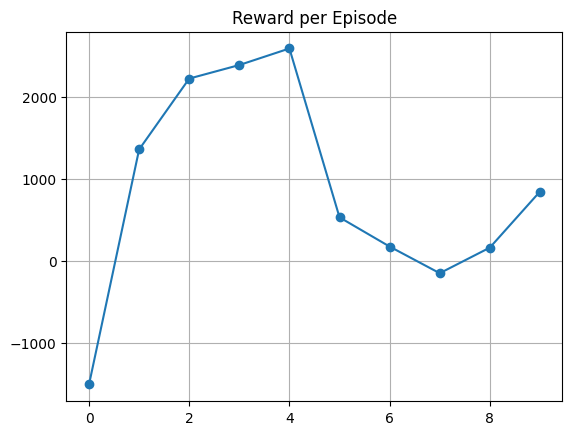

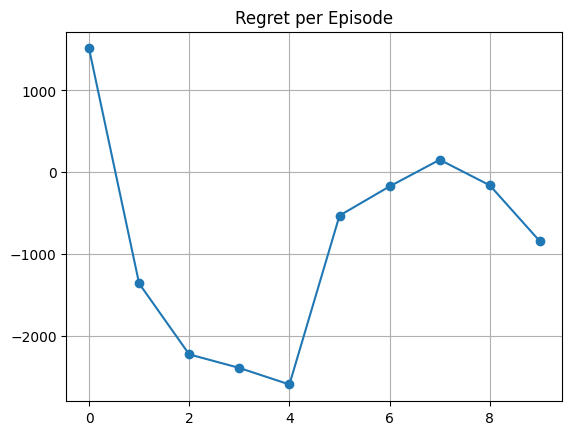

In [ ]:
train_agent(resume=True)   # resumes if a checkpoint exists, else starts fresh

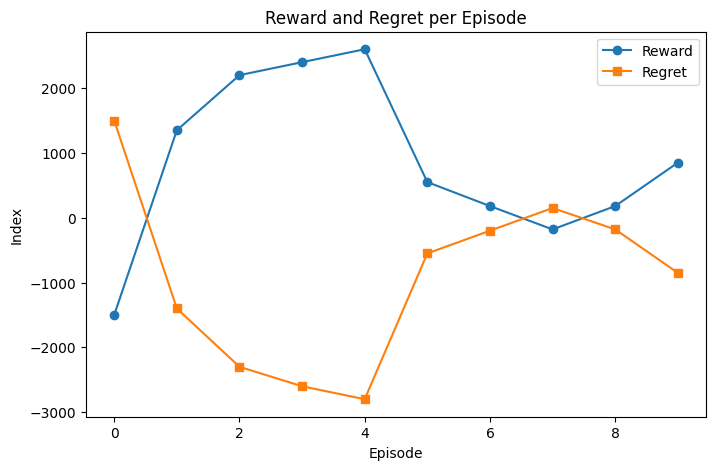

In [ ]:
import matplotlib.pyplot as plt

# Episodes
x = list(range(10))

# From your "Reward per Episode" figure (approximate index values)
y_reward = [-1500, 1350, 2200, 2400, 2600, 550, 180, -180, 180, 850]

# From your "Regret per Episode" figure (approximate index values)
y_regret = [1500, -1400, -2300, -2600, -2800, -550, -200, 150, -180, -850]

# Plot both
plt.figure(figsize=(8, 5))
plt.plot(x, y_reward, marker='o', label='Reward')
plt.plot(x, y_regret, marker='s', label='Regret')

plt.title("Reward and Regret per Episode")
plt.xlabel("Episode")
plt.ylabel("Index")
plt.legend()
plt.grid(False)  # no grid lines
plt.show()

In [ ]:
import os, glob

DRIVE_ROOT = "/content/drive/MyDrive"
CKPT_DIR = os.path.join(DRIVE_ROOT, "checkpoints") if os.path.isdir(DRIVE_ROOT) else "./checkpoints"
METRICS_LIVE = os.path.join(CKPT_DIR, "run_metrics_live.csv")

def purge_training_state():
    if os.path.isdir(CKPT_DIR):
        for f in glob.glob(os.path.join(CKPT_DIR, "ckpt_ep*.pt")):
            try: os.remove(f); print("🗑️ deleted:", f)
            except Exception as e: print("⚠️ could not delete", f, "→", e)
    for f in [METRICS_LIVE, "run_metrics.csv"]:
        if os.path.exists(f):
            try: os.remove(f); print("🗑️ deleted:", f)
            except Exception as e: print("⚠️ could not delete", f, "→", e)
    os.makedirs(CKPT_DIR, exist_ok=True)
    print("✅ fresh start ready in:", CKPT_DIR)

purge_training_state()


🗑️ deleted: /content/drive/MyDrive/checkpoints/ckpt_ep0000_step00011711.pt
🗑️ deleted: /content/drive/MyDrive/checkpoints/ckpt_ep0001_step00023422.pt
🗑️ deleted: /content/drive/MyDrive/checkpoints/ckpt_ep0002_step00035133.pt
🗑️ deleted: /content/drive/MyDrive/checkpoints/ckpt_ep0003_step00046844.pt
🗑️ deleted: /content/drive/MyDrive/checkpoints/ckpt_ep0004_step00058555.pt
🗑️ deleted: /content/drive/MyDrive/checkpoints/ckpt_ep0005_step00070266.pt
🗑️ deleted: /content/drive/MyDrive/checkpoints/ckpt_ep0006_step00081977.pt
🗑️ deleted: /content/drive/MyDrive/checkpoints/ckpt_ep0007_step00093688.pt
🗑️ deleted: /content/drive/MyDrive/checkpoints/ckpt_ep0008_step00105399.pt
🗑️ deleted: /content/drive/MyDrive/checkpoints/ckpt_ep0009_step00117110.pt
🗑️ deleted: /content/drive/MyDrive/checkpoints/run_metrics_live.csv
🗑️ deleted: run_metrics.csv
✅ fresh start ready in: /content/drive/MyDrive/checkpoints
